# Recopilación de datos de NASA POWER

Este código accede a la API de NASA POWER para recopilar información de una coordenada.

## Librerías

Se usan las siguientes librerías:

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import requests

## Recopilación de datos:
Se recopilan datos de la API de NASA POWER:

In [28]:
url_base = r"https://power.larc.nasa.gov/api/temporal/hourly/point?parameters=T2M&community=RE&longitude={longitude}&latitude={latitude}&start=20201212&end=20201212&format=csv&header=false"

puntos = [(1, 1), (1,2), (2, 1), (2,2)]
temperaturas = []

for (lat, long) in puntos:
    url = url_base.format(longitude=long, latitude=lat)
    df = pd.read_csv(url)

    time_mapping = {"YEAR": "year", "MO": "month", "DY": "day", "HR": "hour"}
    df = df.rename(columns=time_mapping)
    df["time"] = pd.to_datetime(df[time_mapping.values()])
    df = df.drop(columns=time_mapping.values())
    df = df.set_index("time")

    temperaturas.append(np.average(df['T2M']))

print([i for i in temperaturas])

[np.float64(27.306250000000002), np.float64(27.249583333333334), np.float64(27.53125), np.float64(27.461249999999996)]


## Gráfico (no terminado)
Se genera usando matplotlib un diagrama de calor:

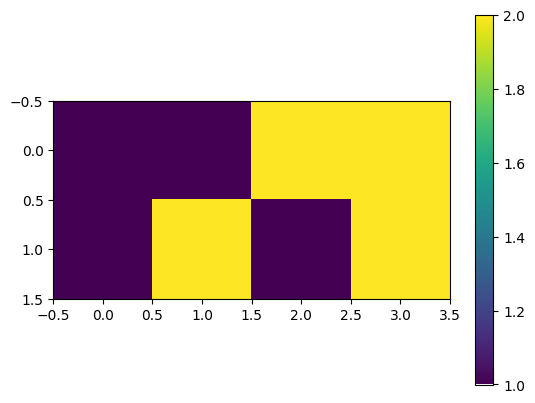

In [33]:
plt.imshow([[i[0] for i in puntos], [i[1] for i in puntos]])
plt.colorbar()